# Öneri Sistemleri

Öneri sistemleri, kullanıcıların geçmiş tercihlerine dayanarak onlara ürünler önermek için kullanılır. Öneri sistemleri genel olarak aşağıdaki kategorilere ayrılır:

- **İçerik tabanlı (Content-based)**: Ürün özelliklerinin (ör. anahtar kelimeler, kategoriler) ve kullanıcı tercihlerinin benzerliğine dayanır.  
  Örneğin, bir kullanıcı Ürün A’yı beğendiyse, öneri sistemi benzer özelliklere sahip ürünleri önerir. Filmler üzerinden konuşursak, bu özellikler yapımcı, tür vb. olabilir. Genellikle bu yaklaşım, denetimli bir ikili sınıflandırma algoritması ile uygulanabilir.

- **İşbirlikçi filtreleme (Collaborative filtering)**: Benzerliği kullanıcı–ürün etkileşimlerinden (ör. puanlar, satın alma sayısı, beğeniler vb.) hesaplar.  
  Bu yöntem, benzer tercihlere sahip müşterileri bulur ve ardından bir müşteriye, onun henüz deneyimlemediği fakat benzer profildeki diğer müşteriler tarafından tercih edilen ürünleri önerir. Sistem, benzer film izleme alışkanlıklarına sahip kullanıcıların genel olarak benzer tercihlere sahip olduğu varsayımını yapar. Kullanıcının izlediklerine benzer videolar izleyen diğer kullanıcıları bulur, ardından bu kullanıcıların izlediği fakat ilk kullanıcının henüz izlemediği videoları önerir. Bu yaklaşımın 3 türü vardır: kullanıcı–kullanıcı işbirlikçi filtreleme, ürün–ürün işbirlikçi filtreleme ve matris çarpanlarına ayırma (matrix factorization).

- Daha yeni ve genellikle daha güçlü yaklaşımlar ise **Hibrit sistemlerdir (Hybrid systems)**.  
  Bu sistemler, yukarıda bahsedilen iki yöntemi birleştirir.

<img src="https://wagon-public-datasets.s3.amazonaws.com/data-science-images/05-ML/06-Unsupervised-Learning/recommendation_systems.png" width=600>

Yukarıdaki diyagram, bir öneri sistemi oluşturmak için kullanılan farklı metodolojileri detaylı bir şekilde sınıflandırmaktadır.

Daha sonra örnek veri seti olarak kullanılacak olan `movieLens` bağlamında:
- İçerik benzerliğine (ör. tür, oyuncu kadrosu vb.) dayalı olarak farklı filmler önerebiliriz; bu durumda **ürün-içerik (item-content) filtreleme** uygulanır.
- Kullanıcı meta verilerini (ör. yaş, cinsiyet) karşılaştırarak, benzer kullanıcıların beğendiği ürünleri bir kullanıcıya önerebiliriz; bu durumda **kullanıcı-içerik (user-content) filtreleme** kullanılır. Ancak `movieLens` veri seti kullanıcı içerik verilerini içermediği için, yalnızca **ürün-ürün (item-item) işbirlikçi filtreleme** oluşturacağız.

**Bellek tabanlı (Memory-based) içerik filtreleme**

Bellek tabanlı yöntemlerde, veriden öğrenip tahmin yapan bir model yoktur. Bunun yerine, film önerileri için kullanılabilecek **önceden hesaplanmış bir benzerlik matrisi** oluşturulur.

## Veri toplama ve temizleme

Aşağıdaki satırları çalıştırarak gerekli veri kümelerini indirin. Ardından, veri kümelerini üç farklı pandas DataFrame'e (`movies`, `tags` ve `ratings`) yükleyin.

In [1]:
!curl https://d32aokrjazspmn.cloudfront.net/materials/movie_ratings.csv > data/movies.csv
!curl https://d32aokrjazspmn.cloudfront.net/materials/movie_tags.csv > data/tags.csv
!curl https://d32aokrjazspmn.cloudfront.net/materials/movie_titles.csv > data/ratings.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0 2425k    0 16991    0     0  10048      0  0:04:07  0:00:01  0:04:06 10089
 19 2425k   19  481k    0     0   179k      0  0:00:13  0:00:02  0:00:11  179k
 41 2425k   41  994k    0     0   265k      0  0:00:09  0:00:03  0:00:06  265k
 59 2425k   59 1444k    0     0   307k      0  0:00:07  0:00:04  0:00:03  308k
 93 2425k   93 2260k    0     0   397k      0  0:00:06  0:00:05  0:00:01  452k
100 2425k  100 2425k    0     0   413k      0  0:00:05  0:00:05 --:--:--  576k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:-

In [6]:
import pandas as pd

movies = pd.read_csv("data/movies.csv")
tags = pd.read_csv("data/tags.csv")
ratings = pd.read_csv("data/ratings.csv")

movies.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


__Farklı film türlerini ayıran ‘|’ işaretini kaldırın ve boşluk ile değiştirin.__

In [13]:
import pandas as pd

movies, ratings = ratings, movies

movies["genres"] = movies["genres"].str.replace("|", " ", regex=False)
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy Romance
3,4,Waiting to Exhale (1995),Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy


__`movies` veri çerçevesini filtreleyerek, yalnızca puan almış filmleri elde edin.__

In [15]:
movies = movies[movies["movieId"].isin(ratings["movieId"])]
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy Romance
3,4,Waiting to Exhale (1995),Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy


### 🧪 Kodunu Test Et

In [14]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'datasets',
    movies_shape=movies.shape,
    tags_shape=tags.shape,
    ratings_shape=ratings.shape,
    genres_cleaned=movies['genres'].str.find('|') >= 0
)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.13, pytest-9.0.3, pluggy-1.6.0 -- c:\Users\BÜŞRA\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: d:\DOSYALARIM\workintech gh\S17D3-S-data-movie-recommendation-main\tests
plugins: anyio-4.13.0, dash-4.4.1
collecting ... collected 4 items

test_datasets.py::TestDatasets::test_genres_are_cleaned PASSED           [ 25%]
test_datasets.py::TestDatasets::test_movies_shape PASSED                 [ 50%]
test_datasets.py::TestDatasets::test_ratings_shape PASSED                [ 75%]
test_datasets.py::TestDatasets::test_tags_shape PASSED                   [100%]

============================== 4 passed in 0.94s ==============================


💯 You can commit your code:

git add tests/datasets.pickle

git commit -m 'Completed datasets step'

git push origin master



## Özellik Mühendisliği

Bir film hakkında sahip olduğumuz **tüm metin verisi bilgilerini**, yani türü ve etiketleri birleştiren `metadata` adlı yeni bir özellik oluşturacağız.

__`movies` ve `tags` DataFrame'lerini birleştirin.__

In [16]:
movies_tags = movies.merge(tags, on="movieId", how="left")
movies_tags.head()

,movieId,title,genres,userId,tag,timestamp
0,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy,336.0,pixar,1.139046e+09
1,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy,474.0,pixar,1.137207e+09
2,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy,567.0,fun,1.525286e+09
3,2,Jumanji (1995),Adventure Children Fantasy,62.0,fantasy,1.528844e+09
4,2,Jumanji (1995),Adventure Children Fantasy,62.0,magic board game,1.528844e+09


**`metadata` sütununu içeren yeni bir `merged_df` veri çerçevesi oluşturun. Bu sütun, hem etiketlerin (tags) hem de türlerin (genres) birleştirilmiş hâlinden oluşmalıdır.**

Bunun için:
- Önce **etiketleri (tags)** film bazında birleştirin.
- Ardından bu birleştirilmiş etiketleri **genres** sütunu ile birleştirin.

Örneğin *Toy Story* filminin `metadata` sütunu şu şekilde olmalıdır:  
`pixar pixar fun Adventure Animation Children Comedy Fantasy`

👉 `merged_df` en azından şu sütunları içermelidir: `movieId`, `title` ve `metadata`.

In [17]:
# 1) Etiketleri (tags) film bazında birleştir
tags_grouped = tags.groupby("movieId")["tag"].apply(
    lambda x: " ".join(x.astype(str))
).reset_index()
tags_grouped.columns = ["movieId", "tags_combined"]

# 2) movies ile tags_grouped'ı birleştir
merged_df = movies.merge(tags_grouped, on="movieId", how="left")

# Tag'i olmayan filmler için boş string kullan
merged_df["tags_combined"] = merged_df["tags_combined"].fillna("")

# 3) metadata sütununu oluştur: tags + genres
merged_df["metadata"] = merged_df["tags_combined"] + " " + merged_df["genres"]
merged_df["metadata"] = merged_df["metadata"].str.strip()

merged_df = merged_df[["movieId", "title", "metadata"]]
merged_df.head()

,movieId,title,metadata
0,1,Toy Story (1995),pixar pixar fun Adventure Animation Children C...
1,2,Jumanji (1995),fantasy magic board game Robin Williams game A...
2,3,Grumpier Old Men (1995),moldy old Comedy Romance
3,4,Waiting to Exhale (1995),Comedy Drama Romance
4,5,Father of the Bride Part II (1995),pregnancy remake Comedy


### 🧪 Kodunu Test Et

In [18]:
from nbresult import ChallengeResult
import numpy as np

result = ChallengeResult(
    'feature_engineering',
    unique_movies=np.all(merged_df[['movieId']].value_counts() > 1),
    metadata=merged_df[merged_df['title'] == 'Copycat (1995)'],
    merged_df_rows=merged_df.shape[0]
)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.13, pytest-9.0.3, pluggy-1.6.0 -- c:\Users\BÜŞRA\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: d:\DOSYALARIM\workintech gh\S17D3-S-data-movie-recommendation-main\tests
plugins: anyio-4.13.0, dash-4.4.1
collecting ... collected 4 items

test_feature_engineering.py::TestFeatureEngineering::test_merged_df_rows PASSED [ 25%]
test_feature_engineering.py::TestFeatureEngineering::test_metadata_has_genres PASSED [ 50%]
test_feature_engineering.py::TestFeatureEngineering::test_metadata_has_tags PASSED [ 75%]
test_feature_engineering.py::TestFeatureEngineering::test_unicity_of_movies PASSED [100%]

============================== 4 passed in 0.90s ==============================


💯 You can commit your code:

git add tests/feature_engineering.pickle

git commit -m 'Completed feature_engineering step'

git push origin master



## Metadata’dan içerik gizil (latent) matrisi oluşturma

### Count Vectorizer

Bir sonraki adımda, metadata metinlerini vektörlere dönüştürmemiz gerekiyor; böylece bunları makine öğrenmesi algoritmalarına verebiliriz. Makine öğrenmesi modelleri metin verisini doğrudan anlayamaz, bu yüzden kodlamamız gerekir.

Bu amaçla [`CountVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html) kullanarak `metadata` sütununu encode edeceğiz.

Count dönüşümü sonucunda elde ettiğiniz vektörlerden oluşan yeni bir `count_df` veri çerçevesi oluşturun.  
Her satır, ilgili filme ait **frekans vektörünü** temsil edecektir.

In [19]:
from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer(stop_words="english")
count_matrix = count_vectorizer.fit_transform(merged_df["metadata"])

count_df = pd.DataFrame(
    count_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=merged_df["movieId"]
)

count_df.head()

,06,1900s,1920s,1950s,1960s,1970s,1980s,1990s,2001,250,...,wrongful,wry,york,younger,zellweger,zither,zoe,zombie,zombies,zooey
movieId,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Boyut indirgeme

Her bir filmin metadata’sı yaklaşık **1675 uzunluğunda bir vektöre** dönüştürüldü!

Önceki derslerde gördüğümüz gibi, veriyi (filmleri) çok fazla bilgi kaybı olmadan temsil edebilmek için **boyut indirgeme** yöntemleri uygulayabiliriz. **Truncated Singular Value Decomposition (SVD)**, boyut indirgeme için kullanılan başka bir gelişmiş araçtır.

PCA’nın aksine, bu yöntem **tekil değer ayrışımını (SVD) hesaplamadan önce veriyi merkezlemez**. Bu da onun **seyrek (sparse) matrislerle verimli şekilde çalışabilmesini** sağlar. Özellikle terim sayım / frekans matrisleri üzerinde iyi çalışır. Bu bağlamda, **Latent Semantic Analysis (LSA)** olarak da bilinir.

Scikit-Learn’deki [`TruncatedSVD`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) sınıfına göz atabilirsiniz; prensip olarak PCA ile aynıdır.

__👉 **Count matrinizin boyutunu azaltmak için (örneğin 25 feature olacak şekilde) Truncated SVD uygulayın.**__


In [20]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=25, random_state=42)
latent_matrix = svd.fit_transform(count_matrix)

latent_df = pd.DataFrame(
    latent_matrix,
    index=merged_df["movieId"]
)

latent_df.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
movieId,,,,,,,,,,,,,,,,,,,,,
1,0.906946,0.969612,-0.642147,-0.496715,0.916093,0.982556,-0.730280,0.424489,0.068656,-0.213954,...,-0.130425,-0.211222,-0.014320,0.018591,0.003824,-0.039222,-0.074825,-0.004178,-0.037505,-0.001531
2,0.412993,0.161520,-0.589471,-0.697434,1.038275,1.271058,-0.499947,0.377932,0.385751,0.340000,...,0.576782,-0.207436,0.020372,-0.017218,0.009734,-0.015241,-0.090534,-0.019570,-0.014867,0.000143
3,0.765626,0.916211,0.122049,0.018001,-0.281955,0.207152,0.653873,0.063522,-0.031535,0.004238,...,-0.012512,-0.061190,0.001084,0.004300,-0.004157,0.005158,0.004476,0.005921,-0.001285,-0.005931
4,1.413731,0.503254,0.641974,-0.225147,-0.260513,0.088929,0.437675,-0.028976,-0.023642,-0.003315,...,-0.019017,-0.078481,-0.030055,0.008139,-0.012147,-0.000817,0.006722,0.005786,0.002877,-0.005983
5,0.523686,0.780103,-0.056799,0.187916,-0.098330,-0.146743,-0.155329,-0.108346,-0.106465,0.029363,...,-0.026957,-0.006599,-0.004276,0.005794,-0.004677,0.011976,0.004103,0.012745,-0.014701,-0.040927


👉 **Toplam açıklanan varyans oranını bileşen sayısının bir fonksiyonu olarak grafiğe çizin.**

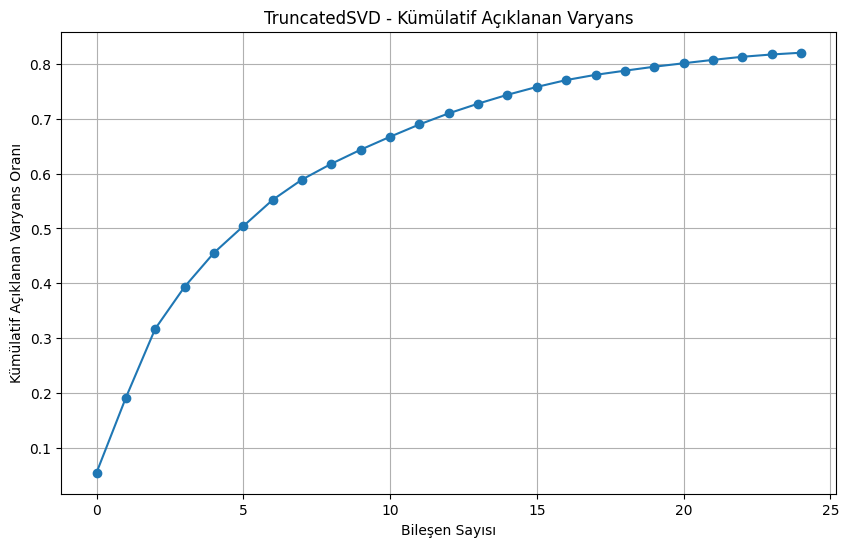

In [23]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o')
plt.xlabel("Bileşen Sayısı")
plt.ylabel("Kümülatif Açıklanan Varyans Oranı")
plt.title("TruncatedSVD - Kümülatif Açıklanan Varyans")
plt.grid(True)
plt.show()

Sadece ilk 25 bileşenle (başlangıçta yaklaşık 1700 olan) varyansın **%80'inden fazlasını** açıklayabildiğimizi görüyoruz, bu da çalışma amaçlarımız için yeterlidir.

👉 **Bu matrisin 25 bileşenini, filmlerin başlıklarına göre indekslenmiş yeni bir `latent_df` veri çerçevesine kaydedin.**

In [25]:
latent_df = pd.DataFrame(
    latent_matrix,
    index=merged_df["title"]
)

latent_df.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
title,,,,,,,,,,,,,,,,,,,,,
Toy Story (1995),0.906946,0.969612,-0.642147,-0.496715,0.916093,0.982556,-0.730280,0.424489,0.068656,-0.213954,...,-0.130425,-0.211222,-0.014320,0.018591,0.003824,-0.039222,-0.074825,-0.004178,-0.037505,-0.001531
Jumanji (1995),0.412993,0.161520,-0.589471,-0.697434,1.038275,1.271058,-0.499947,0.377932,0.385751,0.340000,...,0.576782,-0.207436,0.020372,-0.017218,0.009734,-0.015241,-0.090534,-0.019570,-0.014867,0.000143
Grumpier Old Men (1995),0.765626,0.916211,0.122049,0.018001,-0.281955,0.207152,0.653873,0.063522,-0.031535,0.004238,...,-0.012512,-0.061190,0.001084,0.004300,-0.004157,0.005158,0.004476,0.005921,-0.001285,-0.005931
Waiting to Exhale (1995),1.413731,0.503254,0.641974,-0.225147,-0.260513,0.088929,0.437675,-0.028976,-0.023642,-0.003315,...,-0.019017,-0.078481,-0.030055,0.008139,-0.012147,-0.000817,0.006722,0.005786,0.002877,-0.005983
Father of the Bride Part II (1995),0.523686,0.780103,-0.056799,0.187916,-0.098330,-0.146743,-0.155329,-0.108346,-0.106465,0.029363,...,-0.026957,-0.006599,-0.004276,0.005794,-0.004677,0.011976,0.004103,0.012745,-0.014701,-0.040927


### 🧪 Kodunu Test Et

In [24]:
from nbresult import ChallengeResult

result =  ChallengeResult(
    'metadata',
    counter_shape=count_df.shape,
    latent_shape=latent_df.shape
)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.13, pytest-9.0.3, pluggy-1.6.0 -- c:\Users\BÜŞRA\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: d:\DOSYALARIM\workintech gh\S17D3-S-data-movie-recommendation-main\tests
plugins: anyio-4.13.0, dash-4.4.1
collecting ... collected 3 items

test_metadata.py::TestMetadata::test_counter_columns PASSED              [ 33%]
test_metadata.py::TestMetadata::test_counter_rows PASSED                 [ 66%]
test_metadata.py::TestMetadata::test_features_number PASSED              [100%]

============================== 3 passed in 0.05s ==============================


💯 You can commit your code:

git add tests/metadata.pickle

git commit -m 'Completed metadata step'

git push origin master



## Kullanıcı Derecelendirmelerinden Latent Matris Oluşturma

Meta veriler dışında, bir başka değerli bilgi kaynağımız daha var: **kullanıcı derecelendirmeleri**. 

Bir öneri sistemi, kullanıcı derecelendirmelerine dayanarak benzer bir film önerebilir (öğeden öğeye işbirliğine dayalı filtreleme).

👉 **Aşağıdaki veri setini, filmleri satırlara, `userId`'leri sütunlara yerleştirecek şekilde hazırlıyoruz.**

In [26]:
# Merge
ratings1 = pd.merge(movies[['movieId']], ratings, on="movieId", how="right")
# Pivot
ratings2 = ratings1.pivot(index = 'movieId', columns ='userId', values = 'rating').fillna(0)
display(ratings2.head())
ratings2.shape

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,0.0,4.0,0.0,4.5,0.0,0.0,0.0,...,4.0,0.0,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,...,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0,0.0
3,4.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


(9724, 610)

Kullanıcıların puanlarını 9724 uzunluğunda vektörler olarak içeren bir veri kümesi oluşturduk.

👉**Yine, ilk 200 bileşeni saklamak için `ratings2` veri çerçevesine SVD uygulayacağız. Bu veri çerçevesine `latent_df_2` adını verin.**

In [27]:
svd2 = TruncatedSVD(n_components=200, random_state=42)
latent_matrix_2 = svd2.fit_transform(ratings2)

latent_df_2 = pd.DataFrame(
    latent_matrix_2,
    index=ratings2.index
)

latent_df_2.head()

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
movieId,,,,,,,,,,,,,,,,,,,,,
1,37.649828,-6.380094,-14.994617,-0.286947,1.887147,-4.790050,-8.807629,-2.198637,-1.153304,-1.387562,...,1.509259,2.571558,1.079884,-1.489578,1.162201,-0.635675,0.914679,-0.016347,0.754628,-2.552653
2,20.596193,-0.477880,-10.865916,8.635795,3.072411,0.517149,-4.359215,-3.821408,3.394117,-0.236474,...,0.741599,-0.827772,0.439950,1.747872,0.308577,1.728965,0.808715,0.755086,-1.051243,1.672944
3,8.504182,-5.714924,-3.441693,6.382810,-0.024162,0.783432,1.423027,-0.542292,-3.270655,-1.897238,...,0.261826,-0.553680,-0.386709,0.085206,-0.116957,-0.844441,0.335339,-0.345159,1.245748,0.182475
4,0.465720,-0.828101,-0.954583,0.239080,0.735695,0.877414,-0.214720,-0.527368,-0.079467,-0.015616,...,-0.063262,0.347930,0.193935,0.054893,-0.171441,0.137140,-0.180395,0.195418,0.011186,0.740383
5,6.071045,-2.673536,-4.698195,4.415807,3.714221,1.673627,-1.297653,-1.308023,-1.325734,-1.229592,...,-0.141982,-0.253920,-0.206540,0.256493,0.425539,-0.030499,1.036760,-1.443857,0.583250,0.836855


**👉 Film Adına Göre Yeniden Dizin Oluştur.**

In [28]:
# ratings2'nin indeksi movieId, bunu title'a çevirmemiz gerekiyor
movie_id_to_title = merged_df.set_index("movieId")["title"]

latent_df_2.index = latent_df_2.index.map(movie_id_to_title)

latent_df_2.head()

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
movieId,,,,,,,,,,,,,,,,,,,,,
Toy Story (1995),37.649828,-6.380094,-14.994617,-0.286947,1.887147,-4.790050,-8.807629,-2.198637,-1.153304,-1.387562,...,1.509259,2.571558,1.079884,-1.489578,1.162201,-0.635675,0.914679,-0.016347,0.754628,-2.552653
Jumanji (1995),20.596193,-0.477880,-10.865916,8.635795,3.072411,0.517149,-4.359215,-3.821408,3.394117,-0.236474,...,0.741599,-0.827772,0.439950,1.747872,0.308577,1.728965,0.808715,0.755086,-1.051243,1.672944
Grumpier Old Men (1995),8.504182,-5.714924,-3.441693,6.382810,-0.024162,0.783432,1.423027,-0.542292,-3.270655,-1.897238,...,0.261826,-0.553680,-0.386709,0.085206,-0.116957,-0.844441,0.335339,-0.345159,1.245748,0.182475
Waiting to Exhale (1995),0.465720,-0.828101,-0.954583,0.239080,0.735695,0.877414,-0.214720,-0.527368,-0.079467,-0.015616,...,-0.063262,0.347930,0.193935,0.054893,-0.171441,0.137140,-0.180395,0.195418,0.011186,0.740383
Father of the Bride Part II (1995),6.071045,-2.673536,-4.698195,4.415807,3.714221,1.673627,-1.297653,-1.308023,-1.325734,-1.229592,...,-0.141982,-0.253920,-0.206540,0.256493,0.425539,-0.030499,1.036760,-1.443857,0.583250,0.836855


In [29]:
latent_df_2.shape

(9724, 200)

### 🧪 Kodunu Test Et

In [30]:
from nbresult import ChallengeResult

result = ChallengeResult('ratings', latent_shape=latent_df_2.shape)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.13, pytest-9.0.3, pluggy-1.6.0 -- c:\Users\BÜŞRA\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: d:\DOSYALARIM\workintech gh\S17D3-S-data-movie-recommendation-main\tests
plugins: anyio-4.13.0, dash-4.4.1
collecting ... collected 1 item

test_ratings.py::TestRatings::test_latent_shape PASSED                   [100%]

============================== 1 passed in 0.05s ==============================


💯 You can commit your code:

git add tests/ratings.pickle

git commit -m 'Completed ratings step'

git push origin master



## İçerik ve İşbirlikçi (Collaborative) Matrislerde Kosinüs Benzerliği Uygulama

Sonraki adımda, oluşturduğumuz filtreleme yöntemlerine dayanarak **“Toy Story” filmine en çok benzeyen ilk $N$ filmi** bulmak için bir benzerlik ölçüsü kullanacağız. Kullanabileceğimiz benzerlik ölçülerinden biri **Kosinüs Benzerliği**dir. Scikit-learn’de bu işlem için [`cosine_similarity`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) fonksiyonu bulunur.

👉 **Örnek bir film (“Toy Story”) için hem içerik (metadata) hem de işbirlikçi (puanlar) latent matrislerine karşı kosinüs benzerliğini hesaplayın.**

In [31]:
from sklearn.metrics.pairwise import cosine_similarity

movie_title = "Toy Story (1995)"

# İçerik tabanlı (content-based) benzerlik
content_similarity = cosine_similarity(
    latent_df.loc[[movie_title]], latent_df
)[0]
content_similarity = pd.Series(content_similarity, index=latent_df.index)

# İşbirlikçi filtreleme (collaborative) benzerliği
collaborative_similarity = cosine_similarity(
    latent_df_2.loc[[movie_title]], latent_df_2
)[0]
collaborative_similarity = pd.Series(collaborative_similarity, index=latent_df_2.index)

content_similarity.sort_values(ascending=False).head(10)

title
Toy Story (1995)                                           1.000000
Shrek the Third (2007)                                     0.999663
Asterix and the Vikings (Astérix et les Vikings) (2006)    0.999663
Moana (2016)                                               0.999663
Adventures of Rocky and Bullwinkle, The (2000)             0.999663
Monsters, Inc. (2001)                                      0.999663
Emperor's New Groove, The (2000)                           0.999663
Tale of Despereaux, The (2008)                             0.999663
Turbo (2013)                                               0.999663
The Good Dinosaur (2015)                                   0.999663
dtype: float64

Ayrıca, içerik ve işbirliğine dayalı filtrelemenin benzerlik ortalamasını alan bir hibrit filtre de oluşturabiliriz. 

`hybrid_similarity = (content_similarity + collaborative_similarity) / 2`

__İçerik ve işbirliğine dayalı filtrelemenin benzerlik ortalamasını hesaplayın.__

In [32]:
hybrid_similarity = (content_similarity + collaborative_similarity) / 2
hybrid_similarity.sort_values(ascending=False).head(10)

title
Toy Story (1995)         1.000000
Toy Story 2 (1999)       0.794487
Monsters, Inc. (2001)    0.776741
Shrek (2001)             0.750040
Bug's Life, A (1998)     0.711927
Finding Nemo (2003)      0.710221
Antz (1998)              0.696524
Toy Story 3 (2010)       0.695249
Aladdin (1992)           0.686210
Ice Age (2002)           0.664918
dtype: float64

__Toy Story ile nihai benzerlikleri içeren bir dataframe oluşturun.__

In [33]:
similarity_df = pd.DataFrame({
    "content_similarity": content_similarity,
    "collaborative_similarity": collaborative_similarity,
    "hybrid_similarity": hybrid_similarity
})

similarity_df = similarity_df.sort_values(by="hybrid_similarity", ascending=False)
similarity_df.head(11)  # ilk satır Toy Story'nin kendisi olacağı için 11 alıyoruz

,content_similarity,collaborative_similarity,hybrid_similarity
Toy Story (1995),1.000000,1.000000,1.000000
Toy Story 2 (1999),0.946801,0.642173,0.794487
"Monsters, Inc. (2001)",0.999663,0.553818,0.776741
Shrek (2001),0.912430,0.587650,0.750040
"Bug's Life, A (1998)",0.896113,0.527741,0.711927
Finding Nemo (2003),0.895501,0.524941,0.710221
Antz (1998),0.999663,0.393385,0.696524
Toy Story 3 (2010),0.913228,0.477271,0.695249
Aladdin (1992),0.795150,0.577269,0.686210
Ice Age (2002),0.895876,0.433960,0.664918


__Data Frame'inizi işbirliğine dayalı benzerlik açısından en benzer olanlara göre sıralayın.__

In [34]:
similarity_df.sort_values(by="collaborative_similarity", ascending=False).head(11)

,content_similarity,collaborative_similarity,hybrid_similarity
Toy Story (1995),1.000000,1.000000,1.000000
Toy Story 2 (1999),0.946801,0.642173,0.794487
Independence Day (a.k.a. ID4) (1996),0.198082,0.625355,0.411718
Jurassic Park (1993),0.198981,0.611037,0.405009
Mission: Impossible (1996),0.222322,0.603415,0.412868
Star Wars: Episode IV - A New Hope (1977),0.094482,0.591968,0.343225
Shrek (2001),0.912430,0.587650,0.750040
"Lion King, The (1994)",0.526536,0.583535,0.555035
Star Wars: Episode VI - Return of the Jedi (1983),0.190899,0.579852,0.385376
Forrest Gump (1994),0.220679,0.579440,0.400060


Elbette Toy Story'yi en benzer film olarak görmelisiniz (her sütun için benzerlik 1).

__Content ve hybrid türe göre sıralama yapabilir ve hangisinin en iyi öneriyi verdiğini görebilirsiniz.__

In [35]:
print("İçerik tabanlı (content) sıralaması:")
print(similarity_df.sort_values(by="content_similarity", ascending=False).head(11))

print("\nHibrit (hybrid) sıralaması:")
print(similarity_df.sort_values(by="hybrid_similarity", ascending=False).head(11))

İçerik tabanlı (content) sıralaması:
                                                    content_similarity  \
Toy Story (1995)                                              1.000000   
Turbo (2013)                                                  0.999663   
Tale of Despereaux, The (2008)                                0.999663   
Wild, The (2006)                                              0.999663   
Asterix and the Vikings (Astérix et les Vikings...            0.999663   
Moana (2016)                                                  0.999663   
Adventures of Rocky and Bullwinkle, The (2000)                0.999663   
Emperor's New Groove, The (2000)                              0.999663   
Antz (1998)                                                   0.999663   
Shrek the Third (2007)                                        0.999663   
The Good Dinosaur (2015)                                      0.999663   

                                                    collaborative_similari

**❓ Gerçekçi bir film öneri sistemi oluşturmak için hangi benzerlik daha iyidir?  Bunu `best_similarity` değişkenine atayın.**

In [36]:
a = 'content'
b = 'collaborative'
c = 'hybrid'
best_similarity = None # fill in with the right answer

### 🧪 Kodunu Test Et

In [37]:
from nbresult import ChallengeResult

result = ChallengeResult('recommender', best_similarity=best_similarity)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.13, pytest-9.0.3, pluggy-1.6.0 -- c:\Users\BÜŞRA\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: d:\DOSYALARIM\workintech gh\S17D3-S-data-movie-recommendation-main\tests
plugins: anyio-4.13.0, dash-4.4.1
collecting ... collected 1 item

test_recommender.py::TestRecommender::test_best_similarity FAILED        [100%]

================================== FAILURES ===================================
____________________ TestRecommender.test_best_similarity _____________________

self = <tests.test_recommender.TestRecommender testMethod=test_best_similarity>

    def test_best_similarity(self):
>       self.assertEqual(
            self.result.best_similarity,
            'hybrid',
            'Which similarity gives Toy Story 2 the closer to the first opus?')
E       AssertionError: None != 'hybrid' : Which similarity gives Toy Story 2 the closer

## 🏁 Aferin!

Kodunuzu GitHub'da commit ve push edebilirsiniz.